# Self-Agreement

The experiment behind the findings page. Four language model jurors grade 544 answers on 99 questions with no answer key: 316 BFF-Bench finance answers and 228 from Kensho's corrected MT-Bench. Each juror reads each answer twice, a one-token gut read and a reasoned read, and agrees with itself when the two give the same verdict. Self-solve, from Kensho's paper No Free Labels, trusts a juror only where it can solve the question itself. Every verdict is scored in Cohen's κ against the majority of three expert labels, where 1 is perfect agreement and 0 is chance.

Self-agreement picks which of a juror's grades to trust better than self-solve, by +0.074 to +0.150 in κ for the four jurors. Inside a jury the two signals tie, and no jury beats the best single judge.

| Prompt | What the model gets |
|---|---|
| [instruction_finance.md](../prompts/instruction_finance.md) | The system message for the finance answers: decide whether the final response answers the question correctly |
| [instruction_math.md](../prompts/instruction_math.md) | The same for the MT-Bench answers, with a math and reasoning grader in place of a finance and accounting one |
| [juror_message.md](../prompts/juror_message.md) | The juror's user message for every gut and reasoned read: the conversation, with no reference answer |
| [own_answer_reference_message.md](../prompts/own_answer_reference_message.md) | The own-answer reference read: the juror's own answer to the question where a reference would go |
| [self_solve.md](../prompts/self_solve.md) | What a juror gets to answer a question itself |
| [grader_message.md](../prompts/grader_message.md) | The grader's user message, with the expert reference as ground truth |
| [gpt_oss_format.md](../prompts/gpt_oss_format.md) | How gpt-oss-20b and gpt-oss-120b get the messages as raw text, for the gut and the reasoned read |
| [thinking_models_format.md](../prompts/thinking_models_format.md) | The same for the Qwen, Nemotron and Kimi models, through their chat templates |
| [safeguard.md](../prompts/safeguard.md) | The same for gpt-oss-safeguard-20b |

Every model output is saved in `runs/`, so a rerun makes only the calls that are missing. As shipped, nothing is missing, so the notebook makes no model calls and needs no keys. Section 3 writes the tables to `results/`, and section 5 the charts to `results/figures/`.

## 1. Settings

In [1]:
import pathlib, sys
# the self_agreement folder: this notebook's parent, or the folder it is run from
ROOT = next(p for p in (pathlib.Path.cwd(), pathlib.Path.cwd().parent) if all((p / d).is_dir() for d in ("data", "lib", "runs")))
sys.path.insert(0, str(ROOT))
FILL_MISSING = True    # call the models for rows missing from runs/ (needs TINKER_API_KEY). As shipped nothing is missing
SAFEGUARD = False      # also fill missing rows of the add-on juror gpt-oss-safeguard-20b, on Modal (needs a Modal account)

In [2]:
# ======================= plumbing: key and table helpers (no need to read) =======================
import numpy as np, pandas as pd
from IPython.display import display, Image
from lib import self_agreement as G, run_stages, tinker_client as TC, figures as F

RES, CHK, PER = G.RESULTS, G.RESULTS / "checks", G.RESULTS / "per_answer"   # main tables, supporting checks, one row per answer
HAS_KEY = TC.load_key()   # TINKER_API_KEY from .env in this folder (copy .env.example) or the environment. Only needed for missing rows
pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 200); pd.set_option("display.width", 250)

def read(name, folder=RES):
    # one table of results/, every float read back exactly, blank text cells as ""
    d = pd.read_csv(folder / f"{name}.csv", float_precision="round_trip")
    return d.fillna({c: "" for c in d.columns if not pd.api.types.is_numeric_dtype(d[c])})

def f3(x): return "" if pd.isna(x) else f"{x:.3f}"
def f2(x): return "" if pd.isna(x) else f"{x:.2f}"
def pct(x, d=0): return "" if pd.isna(x) else f"{100 * x:.{d}f}%"
def ci(v, lo, hi, signed=False):
    f = "{:+.3f}" if signed else "{:.3f}"
    return f"{f.format(v)} [{f.format(lo)}, {f.format(hi)}]"

JURORS = ["gpt-oss-20b", "gpt-oss-120b", "qwen3.6-35b", "nemotron-3-super"]   # the four kept jurors
SET = {"finance": "finance", "mt_bench": "MT-Bench", "all": "all answers"}
JURY = {3: "three jurors", 4: "four jurors", 5: "five jurors"}
RULE = {"majority vote": "majority of four", "gut majority vote": "gut majority",
        "majority vote, a tie goes to gpt-oss-120b": "majority of four, a tie goes to gpt-oss-120b",
        "best single judge (gpt-oss-120b reasoned read)": "best single judge (gpt-oss-120b's reasoned read)"}
def rule_name(rule, juror="", n=4):
    # plain names: the CSV's "majority vote" with four jurors is "majority of four", and so on
    if juror: return f"{juror}, {rule}"
    return RULE.get(rule, rule).replace("of four", {3: "of three", 4: "of four", 5: "of five"}[n])

print("folder:", ROOT.name, "| key:", "set." if HAS_KEY else "not set, fine while every row is saved.")

folder: self_agreement | key: not set, fine while every row is saved.


## 2. Answers and prompts

Kensho's public data, saved in `data/`: three expert votes per answer from VERDICTS, the finance conversations from BFF-Bench and the corrected MT-Bench references from CMTBench. An answer is kept when at least 2 of its 3 experts agree, and their majority is its label. The finance answers are 2 per question turn, in a fixed seeded order. No juror saw a reference answer. Only the grader did, to grade the jurors' own answers. `lib/prompts.py` builds the prompts word for word as in `prompts/`.

In [3]:
ITEMS = G.items()
VOTES = {"unanimous": "all 3 agree", "two_plus_unsure": "2 agree, 1 not sure", "split": "2 agree, 1 disagrees"}
display(pd.crosstab(ITEMS.answer_set.map(SET), ITEMS.group.map(VOTES)).reindex(index=["finance", "MT-Bench"], columns=list(VOTES.values()))
        .rename_axis(index="answer set", columns="how the experts voted"))
print(f"{len(ITEMS)} answers on {ITEMS.question_id.nunique()} questions. The first {len(G.duplicate_ids())} in reading order were read twice (section 3).")

how the experts voted,all 3 agree,"2 agree, 1 not sure","2 agree, 1 disagrees"
answer set,,,
finance,171,95,50
MT-Bench,177,31,20


544 answers on 99 questions. The first 40 in reading order were read twice (section 3).


## 3. Grade

Calls a model only for rows missing from `runs/`. As shipped, every row is there, so this prints that nothing is missing. Every call ran on Oct 24, 2026, on Tinker, Thinking Machines' hosted model service, except the add-on juror gpt-oss-safeguard-20b, which ran on Modal.

In [4]:
# What runs/ holds for each step of the run, and the calls a rerun would still make. Step 0, a smoke test, and step 8, the analysis, left no rows
STEP = pd.read_csv(ROOT / "runs" / "steps.csv").drop_duplicates("stage").set_index("stage").step
st = pd.DataFrame(run_stages.status())
display(pd.DataFrame({"step": st.stage, "what it ran": st.stage.map(STEP), "rows needed": st.expected, "rows saved": st.present,
                      "rows missing": st.missing, "extra rows": st.extra}).set_index("step"))
MISSING = sum(len(v) for v in run_stages.missing().values())
if not MISSING:
    print("Nothing is missing, so no model is called.")
elif FILL_MISSING:
    print(f"{MISSING} rows are missing. Calling the models for them now.")
    print("rows added:", run_stages.run_missing(safeguard=SAFEGUARD))
else:
    print(f"{MISSING} rows are missing. Set FILL_MISSING = True to call the models for them.")

,what it ran,rows needed,rows saved,rows missing,extra rows
step,,,,,
1,grader screening,300,300,0,0
2,juror screening,1200,1200,0,0
3,"self-solve, turn 1",396,396,0,0
4,"self-solve, turn 2",396,396,0,0
5,grading the jurors' own answers,792,792,0,0
6,gut and reasoned reads,4352,4352,0,0
7,repeat reads and own-answer reference reads,2303,2303,0,0
9,gpt-oss-safeguard-20b reads (Modal),1088,1088,0,0


Nothing is missing, so no model is called.


`lib/self_agreement.py` then scores every read and writes every table of `results/`. It reads only `data/` and `runs/`, and ports the analysis of Oct 24, 2026 line by line. Each 95% interval comes from 2,000 resamples of the 99 questions, so this cell takes a few minutes.

In [5]:
S4 = G.summary()                   # four jurors. The keys keep the run's short names, mapped to plain names in lib/self_agreement.py
S5 = G.summary(safeguard=True)     # the same with gpt-oss-safeguard-20b as a fifth juror
WRITTEN = G.write_results()        # every table of results/, from the two runs above
for d in (RES, CHK, PER):
    print(f"{d.relative_to(ROOT)}/:", ", ".join(sorted(p.name for p in WRITTEN if p.parent == d)))

results/: contrasts.csv, coverage.csv, decisions.csv, error_rankers.csv, kappa_by_juror_count.csv, latent_solver.csv, matched_coverage.csv, own_answer_index.csv, results_by_rule.csv, uncovered_fallbacks.csv
results/checks/: answer_sets.csv, duplicates.csv, examinee_pass_rates.csv, examinee_ranking.csv, grader_check.csv, hand_check_sample.md, juror_check.csv, juror_reads.csv, results_parsed_only.csv, self_solve.csv
results/per_answer/: answers.csv, reads.csv


### Screening

Two checks ran first, on finance answers. The candidate graders qwen3.5-397b and kimi-k2.6 graded 150 answers with the expert reference, against a bar of κ 0.80. The one closer to the experts grades the jurors' own answers. Six candidate jurors read the first 100 answers, gut and reasoned.

A gut read is scored by its gut margin, log P(INCORRECT) minus log P(CORRECT) at the verdict token, so a margin below 0 accepts. AUROC, the area under the receiver operating characteristic curve, is the chance that a random correct answer scores better than a random wrong one. A juror was kept if its gut AUROC was at least 0.60 and at least 0.90 of its reasoned reads ended in a verdict. At most 0.05 of its gut margins could be missing. Tables: [grader_check.csv](../results/checks/grader_check.csv), [juror_check.csv](../results/checks/juror_check.csv).

In [6]:
g = read("grader_check", CHK)
yes = {True: "yes", False: "no"}
display(pd.DataFrame({"grader": g.grader, "answers": g.answers, "κ with the reference": g.kappa.map(f3),
                      "correct answers it rejected": [f"{a} of {b}" for a, b in zip(g.label_correct_rejected, g.label_correct)],
                      "no verdict": g.no_verdict, "token limit": g.token_limit.map("{:,}".format), "reaches 0.80": g.passes.map(yes),
                      "grades the own answers": g.chosen.map(yes)}).set_index("grader"))
j = read("juror_check", CHK)
display(pd.DataFrame({"juror": j.juror, "answers": j.answers, "gut AUROC": j.gut_auroc.map(f3), "verdict rate": j.verdict_rate.map(f2),
                      "gut margins missing": j.gut_margin_missing_rate.map(f2), "hit the token limit": j.token_limit_rate.map(pct),
                      "token limit": j.token_limit.map("{:,}".format), "screening": j.kept.map({True: "kept", False: "dropped"})}).set_index("juror"))
chosen = g[g.chosen].iloc[0]
print(("Neither grader reached κ 0.80. " if not g.passes.any() else "") + f"{chosen.grader} grades the jurors' own answers, with the higher κ ({chosen.kappa:.3f}).")
for r in j[~j.kept].itertuples():
    why = [w for w, bad in (("gut AUROC below 0.60", r.gut_auroc < 0.60), ("verdict rate below 0.90", r.verdict_rate < 0.90),
                            ("more than 0.05 of gut margins missing", r.gut_margin_missing_rate > 0.05)) if bad]
    print(f"Dropped {r.juror}: {' and '.join(why)}, with {pct(r.token_limit_rate)} of its reasoned reads at the token limit.")

,answers,κ with the reference,correct answers it rejected,no verdict,token limit,reaches 0.80,grades the own answers
grader,,,,,,,
qwen3.5-397b,150,0.696,19 of 81,0,"8,192",no,yes
kimi-k2.6,150,0.582,29 of 81,4,"8,192",no,no


,answers,gut AUROC,verdict rate,gut margins missing,hit the token limit,token limit,screening
juror,,,,,,,
gpt-oss-20b,100,0.795,0.99,0.00,1%,"4,096",kept
gpt-oss-120b,100,0.782,1.00,0.00,0%,"4,096",kept
qwen3.5-4b,100,0.759,0.63,0.00,37%,"6,144",dropped
qwen3.5-9b,100,0.725,0.75,0.00,25%,"6,144",dropped
qwen3.6-35b,100,0.741,1.00,0.00,0%,"6,144",kept
nemotron-3-super,100,0.709,0.98,0.00,2%,"6,144",kept


Neither grader reached κ 0.80. qwen3.5-397b grades the jurors' own answers, with the higher κ (0.696).
Dropped qwen3.5-4b: verdict rate below 0.90, with 37% of its reasoned reads at the token limit.
Dropped qwen3.5-9b: verdict rate below 0.90, with 25% of its reasoned reads at the token limit.


### Self-solve

Each kept juror answers all 198 question turns itself: turn 1, then turn 2 after its own turn-1 answer. The grader, qwen3.5-397b, grades every own answer against the expert reference, and a juror solved a question turn when its own answer is judged correct. Of the 40 MT-Bench turns, 36 also have a hand-written final-answer key, and the other 4 are open-ended. A turn is contested when the grader gives no verdict or disagrees with the key. As registered, an answer cut at the token limit counts as no answer, and a turn with no own answer counts as unsolved. Table: [self_solve.csv](../results/checks/self_solve.csv). A blank sheet to check 20 of the grades by hand is in [hand_check_sample.md](../results/checks/hand_check_sample.md).

In [7]:
ss = read("self_solve", CHK)
a = ss[ss.answer_set == "all"].set_index("juror")
share = lambda s: ss[ss.answer_set == s].set_index("juror").pipe(lambda x: (x.solved / x.question_turns).map(pct))  # noqa: E731
display(pd.DataFrame({"question turns": a.question_turns, "solved": a.solved, "unsolved": a.unsolved, "contested": a.contested,
                      "unsolved with no own answer": a.no_own_answer, "solved, finance": share("finance"),
                      "solved, MT-Bench": share("mt_bench")}).rename_axis("juror"))
print(f"{a.question_turns.sum()} juror and question turn pairs: {a.solved.sum()} solved, {a.unsolved.sum()} unsolved and {a.contested.sum()} contested. "
      f"The {a.no_own_answer.sum()} with no own answer are among the unsolved.")

,question turns,solved,unsolved,contested,unsolved with no own answer,"solved, finance","solved, MT-Bench"
juror,,,,,,,
gpt-oss-20b,198,124,72,2,37,59%,75%
gpt-oss-120b,198,159,35,4,3,80%,80%
qwen3.6-35b,198,142,52,4,38,69%,82%
nemotron-3-super,198,158,33,7,5,80%,80%


792 juror and question turn pairs: 583 solved, 192 unsolved and 17 contested. The 83 with no own answer are among the unsolved.


### Reads

Each kept juror reads all 544 answers twice, gut and reasoned, at temperature 0 and with no reference. The reasoned read may use up to 4,096 new tokens for gpt-oss-20b and gpt-oss-120b and 6,144 for the thinking models before its verdict. A reasoned read with no verdict counts as a reject. The add-on juror gpt-oss-safeguard-20b read the same answers on Modal. It has no self-solve run, so it never votes in the self-solve jury. The first cell describes the answers, and the second the reads, with one answer as an example. Tables: [answer_sets.csv](../results/checks/answer_sets.csv), [juror_reads.csv](../results/checks/juror_reads.csv), and one row per answer in [answers.csv](../results/per_answer/answers.csv) and per answer and juror in [reads.csv](../results/per_answer/reads.csv).

In [8]:
sets = read("answer_sets", CHK)
display(pd.DataFrame({"answer set": sets.answer_set.map(SET), "answers": sets.answers, "question turns": sets.question_turns,
                      "questions": sets.questions, "labelled correct": sets.label_correct, "answer writers": sets.examinees,
                      "turns with an answer key": sets.answer_key_turns}).set_index("answer set"))
ANS = read("answers", PER)
w = ANS.groupby("examinee").agg(finance=("answer_set", lambda s: int((s == "finance").sum())),
                                mt=("answer_set", lambda s: int((s == "mt_bench").sum())), correct=("label_correct", "mean"))
display(pd.DataFrame({"finance answers": w.finance, "MT-Bench answers": w.mt, "labelled correct": w.correct.map(pct)}).rename_axis("answer writer"))

,answers,question turns,questions,labelled correct,answer writers,turns with an answer key
answer set,,,,,,
finance,316,158,79,181,6,0
MT-Bench,228,40,20,168,6,36
all answers,544,198,99,349,6,36


,finance answers,MT-Bench answers,labelled correct
answer writer,,,
gemma-2-2b,61,38,46%
gpt-4o,44,37,84%
llama-3.3-70b,48,39,75%
phi-4,54,38,68%
qwen2.5-7b,61,38,61%
yi1.5-34b-16k,48,38,55%


In [9]:
jr = read("juror_reads", CHK)
display(pd.DataFrame({"juror": [f"{x} (add-on)" if n == 5 else x for x, n in zip(jr.juror, jr.jurors)], "answers": jr.answers,
                      "no reasoned verdict": jr.no_verdict, "hit the token limit": jr.hit_token_limit, "gut margins missing": jr.gut_margin_missing,
                      "reasoned read accepts": jr.accept_rate_reasoned.map(pct), "gut read accepts": jr.accept_rate_gut.map(pct),
                      "agrees with itself": jr.agrees_with_itself_rate.map(lambda x: pct(x, 1)),
                      "AUROC of its read conflict for its errors": jr.auroc_disagreement_error.map(f3)}).set_index("juror"))
# one answer, read by the four jurors
RD = read("reads", PER)
first = ANS.iloc[0]; ex = RD[(RD.item_id == first.item_id) & RD.juror.isin(JURORS)]
verdict = {1: "accept", 0: "reject", -1: "no verdict"}
display(pd.DataFrame({"juror": ex.juror, "gut margin": ex.gut_margin.map("{:+.2f}".format), "gut read": ex.gut_verdict.map(verdict),
                      "reasoned read": ex.reasoned_verdict.map(verdict), "agrees with itself": ex.agrees_with_itself.map({1: "yes", 0: "no"}),
                      "its question turn": ex.self_solve_status}).set_index("juror"))
print(f"The first answer in reading order ({first.item_id}, {SET[first.answer_set]}, by {first.examinee}) is labelled "
      f"{'correct' if first.label_correct else 'wrong'}. {first.jurors_agreeing} of 4 jurors agree with themselves on it. "
      f"The agreement jury {'accepts' if first.agreement_jury else 'rejects'} it.")

,answers,no reasoned verdict,hit the token limit,gut margins missing,reasoned read accepts,gut read accepts,agrees with itself,AUROC of its read conflict for its errors
juror,,,,,,,,
gpt-oss-20b,544,13,13,0,63%,67%,76.8%,0.751
gpt-oss-120b,544,0,0,0,58%,53%,79.2%,0.686
qwen3.6-35b,544,2,2,0,60%,72%,81.6%,0.746
nemotron-3-super,544,9,9,0,58%,65%,81.1%,0.725
gpt-oss-safeguard-20b (add-on),544,6,6,0,62%,68%,80.0%,0.759


,gut margin,gut read,reasoned read,agrees with itself,its question turn
juror,,,,,
gpt-oss-20b,-2.62,accept,reject,no,solved
gpt-oss-120b,-3.00,accept,reject,no,solved
qwen3.6-35b,-3.38,accept,reject,no,solved
nemotron-3-super,-1.57,accept,reject,no,solved


The first answer in reading order (558aeb4d-t2, finance, by qwen2.5-7b) is labelled correct. 0 of 4 jurors agree with themselves on it. The agreement jury rejects it.


### Repeat reads

Each kept juror read the first 40 answers again, gut and reasoned, as fresh calls at temperature 0. A verdict flip is a reasoned verdict that changed, and a gut flip is a gut margin that changed sign. Table: [duplicates.csv](../results/checks/duplicates.csv).

In [10]:
DU = read("duplicates", CHK)
num = lambda x, f="{:.0f}": "" if pd.isna(x) else f.format(x)  # noqa: E731
display(pd.DataFrame({"answers": DU.answers.values, "verdict flips": DU.verdict_flips.values, "gut flips": DU.gut_flips.map(num).values,
                      "median gut margin change": DU.median_abs_margin_change.map(lambda x: num(x, "{:.3f}")).values,
                      "largest gut margin change": DU.max_abs_margin_change.map(lambda x: num(x, "{:.3f}")).values,
                      "agrees-with-itself flips": DU.agreement_flips.map(num).values},
                     index=pd.Index([rule_name(r) for r in DU.reader], name="read twice")))

,answers,verdict flips,gut flips,median gut margin change,largest gut margin change,agrees-with-itself flips
read twice,,,,,,
gpt-oss-20b,40,3,0,0.121,0.500,3
gpt-oss-120b,40,1,0,0.356,2.502,1
qwen3.6-35b,40,0,0,0.000,0.000,0
nemotron-3-super,40,1,0,0.030,0.877,1
agreement jury,40,1,,,,
majority of four,40,0,,,,


## 4. Results

Every number comes from `lib/self_agreement.py`, through the tables of `results/` that the findings page also reads. Agreement is Cohen's κ against the expert majority, with 95% intervals from resampling the 99 questions. False reject is the share of correct answers a rule rejects, and false accept the share of wrong answers it accepts. A missing verdict counts as a reject.

### Juries

Each rule turns the reads into one verdict per answer.

| Rule | How it decides an answer |
|---|---|
| Agreement jury | The majority reasoned verdict of the jurors that agree with themselves on it. A tie goes to the juror with the largest gut margin in size. With no such juror, the majority of four decides. A juror with no reasoned verdict never agrees with itself |
| Self-solve jury | The same, with the jurors that solved its question turn |
| Majority of four | All four reasoned verdicts. A tie counts as a reject |
| Gut majority | All four gut reads. A tie counts as a reject |
| Best single judge | gpt-oss-120b's reasoned read, the best of the eight single reads on all answers, chosen in hindsight with the expert labels |

Two rules and a third test, the self-solve gap test below, were registered before the run. Rule 1 compares the agreement jury with the self-solve jury on all answers. The agreement jury wins at +0.04 or more with the interval above 0, and the self-solve jury wins at -0.04 or less with the interval below 0. Anything else is a tie. Rule 2, "the jury wins", has two parts. The agreement jury must beat the best single judge by at least +0.03 with the interval above 0, and be at least as good as the majority of four. Pooled κ differences below 0.03 are not interpreted.

The rule that a juror with no reasoned verdict never agrees with itself was set in the run, not the plan. The row "agreement jury, a missing verdict counts as a reject" applies the plan's literal rule, where that missing verdict can match a gut reject. The main jury has the four kept jurors. The three-juror jury, closest to the planned design, leaves out qwen3.6-35b, and the five-juror jury adds gpt-oss-safeguard-20b. Tables: [results_by_rule.csv](../results/results_by_rule.csv), [contrasts.csv](../results/contrasts.csv), [decisions.csv](../results/decisions.csv), [results_parsed_only.csv](../results/checks/results_parsed_only.csv).

In [11]:
R = read("results_by_rule")
ORDER = [("agreement jury", ""), ("self-solve jury", ""), ("majority vote", ""), ("majority vote, a tie goes to gpt-oss-120b", ""),
         ("gut majority vote", ""), ("agreement jury, a missing verdict counts as a reject", "")] + \
        [(m, j) for j in JURORS + ["gpt-oss-safeguard-20b"] for m in ("reasoned read", "gut read")]

def by_rule(n):
    rows = []
    for rule, juror in ORDER:
        c = R[(R.jurors == n) & (R.rule == rule) & (R.juror == juror)].set_index("answer_set")
        if c.empty: continue
        rows.append({"rule": rule_name(rule, juror, n), "finance κ": f3(c.kappa["finance"]), "MT-Bench κ": f3(c.kappa["mt_bench"]),
                     "all answers κ [95% interval]": ci(c.kappa["all"], c.kappa_lo["all"], c.kappa_hi["all"]),
                     "false reject": f2(c.false_reject["all"]), "false accept": f2(c.false_accept["all"])})
    return pd.DataFrame(rows).set_index("rule")

print("Four jurors")
display(by_rule(4))

Four jurors


,finance κ,MT-Bench κ,all answers κ [95% interval],false reject,false accept
rule,,,,,
agreement jury,0.579,0.786,"0.666 [0.592, 0.734]",0.14,0.18
self-solve jury,0.557,0.747,"0.640 [0.557, 0.715]",0.17,0.16
majority of four,0.554,0.793,"0.655 [0.576, 0.729]",0.18,0.13
"majority of four, a tie goes to gpt-oss-120b",0.536,0.813,"0.650 [0.566, 0.725]",0.16,0.17
gut majority,0.494,0.557,"0.532 [0.451, 0.611]",0.19,0.27
"agreement jury, a missing verdict counts as a reject",0.567,0.776,"0.655 [0.581, 0.724]",0.15,0.18
"gpt-oss-20b, reasoned read",0.471,0.756,"0.587 [0.501, 0.663]",0.16,0.25
"gpt-oss-20b, gut read",0.495,0.552,"0.525 [0.439, 0.602]",0.15,0.33
"gpt-oss-120b, reasoned read",0.519,0.793,"0.633 [0.550, 0.711]",0.18,0.16


In [12]:
# The registered differences, agreement jury minus each comparison, on all answers, for each jury
C = read("contrasts")
def diff(n, rule, minus, s="all"):
    x = C[(C.jurors == n) & (C.rule == rule) & (C.minus == minus) & (C.answer_set == s)]
    return ci(x["difference"].iloc[0], x["lo"].iloc[0], x["hi"].iloc[0], signed=True) if len(x) else ""
MINUS = {"self-solve jury": "self-solve jury (rule 1)", "best single judge (gpt-oss-120b reasoned read)": "best single judge (rule 2)",
         "best single judge, chosen again in each resample": "best single judge, chosen again in each resample",
         "majority vote": "majority of the jury (rule 2)"}
display(pd.DataFrame([{"agreement jury minus": lab, **{JURY[n]: diff(n, "agreement jury", m) for n in (4, 3, 5)}} for m, lab in MINUS.items()])
        .set_index("agreement jury minus"))
display(pd.DataFrame([{"agreement jury minus, four jurors": MINUS[m], **{SET[s]: diff(4, "agreement jury", m, s) for s in ("finance", "mt_bench")}}
                      for m in ("self-solve jury", "best single judge (gpt-oss-120b reasoned read)", "majority vote")]).set_index("agreement jury minus, four jurors"))
OTHER = [("self-solve jury", "majority vote"), ("self-solve jury", "best single judge (gpt-oss-120b reasoned read)"),
         ("majority vote", "best single judge (gpt-oss-120b reasoned read)"), ("gut majority vote", "majority vote")]
display(pd.DataFrame([{"other differences, four jurors, all answers": f"{rule_name(a)} minus {rule_name(b)}", "difference [95% interval]": diff(4, a, b)}
                      for a, b in OTHER]).set_index("other differences, four jurors, all answers"))
D = read("decisions")
display(D[D.decision.str.startswith("rule")].pivot(index="decision", columns="jurors", values="outcome")[[4, 3, 5]].rename(columns=JURY)
        .rename_axis(index="registered rule", columns=None))
same = all(S4[k] == [float(v) for v in C[(C.jurors == 4) & (C.rule == "agreement jury") & (C.minus == m) & (C.answer_set == "all")]
                     [["difference", "lo", "hi"]].iloc[0]]
           for k, m in (("J1", "self-solve jury"), ("J2a", "best single judge (gpt-oss-120b reasoned read)"), ("J2b", "majority vote")))
print("summary() holds the same three differences as contrasts.csv, to the last bit:", same)

,four jurors,three jurors,five jurors
agreement jury minus,,,
self-solve jury (rule 1),"+0.026 [-0.020, +0.072]","+0.022 [-0.017, +0.066]","+0.015 [-0.040, +0.071]"
best single judge (rule 2),"+0.033 [-0.011, +0.081]","+0.019 [-0.023, +0.065]","+0.028 [-0.027, +0.088]"
"best single judge, chosen again in each resample","+0.033 [-0.021, +0.071]",,"+0.028 [-0.037, +0.059]"
majority of the jury (rule 2),"+0.011 [-0.033, +0.052]","+0.007 [-0.031, +0.049]","+0.005 [-0.045, +0.054]"


,finance,MT-Bench
"agreement jury minus, four jurors",,
self-solve jury (rule 1),"+0.021 [-0.041, +0.088]","+0.040 [-0.022, +0.121]"
best single judge (rule 2),"+0.059 [-0.005, +0.127]","-0.007 [-0.057, +0.046]"
majority of the jury (rule 2),"+0.025 [-0.034, +0.083]","-0.007 [-0.069, +0.059]"


,difference [95% interval]
"other differences, four jurors, all answers",
self-solve jury minus majority of four,"-0.015 [-0.046, +0.016]"
self-solve jury minus best single judge (gpt-oss-120b's reasoned read),"+0.007 [-0.036, +0.053]"
majority of four minus best single judge (gpt-oss-120b's reasoned read),"+0.022 [-0.017, +0.064]"
gut majority minus majority of four,"-0.123 [-0.207, -0.040]"


,four jurors,three jurors,five jurors
registered rule,,,
rule 1: agreement jury against self-solve jury,tie,tie,tie
rule 2: the jury wins,not met,not met,not met


summary() holds the same three differences as contrasts.csv, to the last bit: True


In [13]:
# The same rules with three and five jurors, and scored on the answers with a verdict only (a missing verdict abstains)
for n in (3, 5):
    print(JURY[n].capitalize())
    display(by_rule(n))
P = read("results_parsed_only", CHK)
p = P[(P.jurors == 4) & (P.juror == "")]
display(pd.DataFrame({"four jurors, a missing verdict abstains": [rule_name(r) for r in p.rule], "answers scored": p.answers.values,
                      "κ": p.kappa.map(f3).values}).set_index("four jurors, a missing verdict abstains"))

Three jurors


,finance κ,MT-Bench κ,all answers κ [95% interval],false reject,false accept
rule,,,,,
agreement jury,0.561,0.776,"0.652 [0.576, 0.720]",0.15,0.18
self-solve jury,0.517,0.791,"0.630 [0.547, 0.706]",0.17,0.18
majority of three,0.535,0.801,"0.645 [0.562, 0.718]",0.16,0.18
"majority of three, a tie goes to gpt-oss-120b",0.535,0.801,"0.645 [0.562, 0.718]",0.16,0.18
gut majority,0.497,0.544,"0.527 [0.445, 0.605]",0.18,0.29
"agreement jury, a missing verdict counts as a reject",0.555,0.766,"0.645 [0.570, 0.712]",0.16,0.18
"gpt-oss-20b, reasoned read",0.471,0.756,"0.587 [0.501, 0.663]",0.16,0.25
"gpt-oss-20b, gut read",0.495,0.552,"0.525 [0.439, 0.602]",0.15,0.33
"gpt-oss-120b, reasoned read",0.519,0.793,"0.633 [0.550, 0.711]",0.18,0.16


Five jurors


,finance κ,MT-Bench κ,all answers κ [95% interval],false reject,false accept
rule,,,,,
agreement jury,0.575,0.784,"0.661 [0.589, 0.730]",0.13,0.21
self-solve jury,0.568,0.747,"0.646 [0.565, 0.721]",0.17,0.17
majority of five,0.560,0.791,"0.656 [0.577, 0.730]",0.15,0.17
"majority of five, a tie goes to gpt-oss-120b",0.560,0.791,"0.656 [0.577, 0.730]",0.15,0.17
gut majority,0.507,0.589,"0.551 [0.468, 0.626]",0.14,0.31
"agreement jury, a missing verdict counts as a reject",0.563,0.774,"0.651 [0.576, 0.719]",0.13,0.21
"gpt-oss-20b, reasoned read",0.471,0.756,"0.587 [0.501, 0.663]",0.16,0.25
"gpt-oss-20b, gut read",0.495,0.552,"0.525 [0.439, 0.602]",0.15,0.33
"gpt-oss-120b, reasoned read",0.519,0.793,"0.633 [0.550, 0.711]",0.18,0.16


,answers scored,κ
"four jurors, a missing verdict abstains",,
majority of four,544,0.662
gut majority,544,0.532
agreement jury,544,0.666
self-solve jury,544,0.644


### Routing at matched coverage

Routing means choosing which of a juror's answers to trust. For a fair comparison, each juror keeps the same number of answers under every rule, as many as fall on the question turns it solved. A juror's conflict on an answer is its gut margin when its reasoned read accepts, and minus that margin when it rejects. So a low conflict means the gut read firmly backs the reasoned verdict.

Self-solve keeps the answers on the turns the juror solved. Self-agreement keeps the answers with the least conflict. Confidence keeps the answers whose gut margins are largest in size. Random draws 1,000 sets of the same size. Each rule is scored by the κ of the juror's reasoned read on the answers it keeps, and gut confidence by its gut read. This comparison was planned, but no decision rule was set for it before the run. Table: [matched_coverage.csv](../results/matched_coverage.csv).

In [14]:
M = read("matched_coverage").set_index("juror").reindex(JURORS)
display(pd.DataFrame({"answers kept": [f"{k} ({pct(c, 1)})" for k, c in zip(M.answers_kept, M.coverage)],
                      "self-solve": M.kappa_self_solve.map(f3), "self-agreement": M.kappa_self_agreement.map(f3),
                      "confidence, reasoned read": M.kappa_reasoned_confidence.map(f3), "confidence, gut read": M.kappa_gut_confidence.map(f3),
                      "random, mean": M.kappa_random_mean.map(f3), "random, 95th percentile": M.kappa_random_95th.map(f3)}).rename_axis("juror"))
d = lambda c: [ci(v, lo, hi, signed=True) for v, lo, hi in zip(M[c], M[c + "_lo"], M[c + "_hi"])]  # noqa: E731
display(pd.DataFrame({"self-agreement minus self-solve": d("self_agreement_minus_self_solve"),
                      "minus confidence, reasoned read": d("self_agreement_minus_reasoned_confidence"),
                      "minus confidence, gut read": d("self_agreement_minus_gut_confidence")}, index=M.index))
below, wins, sure = (int(x.sum()) for x in (M.kappa_self_solve < M.kappa_random_95th, M.self_agreement_minus_self_solve > 0,
                                             M.self_agreement_minus_self_solve_lo > 0))
print(f"Self-solve routing is below the random 95th percentile for {below} of {len(M)} jurors. "
      f"Self-agreement beats self-solve for {wins} of {len(M)}, with the interval above 0 for {sure}.")

,answers kept,self-solve,self-agreement,"confidence, reasoned read","confidence, gut read","random, mean","random, 95th percentile"
juror,,,,,,,
gpt-oss-20b,365 (67.1%),0.596,0.746,0.670,0.647,0.587,0.627
gpt-oss-120b,439 (80.7%),0.641,0.715,0.688,0.574,0.633,0.660
qwen3.6-35b,406 (74.6%),0.576,0.686,0.701,0.626,0.614,0.648
nemotron-3-super,436 (80.1%),0.605,0.682,0.618,0.584,0.604,0.633


,self-agreement minus self-solve,"minus confidence, reasoned read","minus confidence, gut read"
juror,,,
gpt-oss-20b,"+0.150 [+0.063, +0.254]","+0.076 [+0.024, +0.149]","+0.099 [+0.038, +0.171]"
gpt-oss-120b,"+0.074 [-0.005, +0.159]","+0.027 [-0.028, +0.080]","+0.141 [+0.065, +0.208]"
qwen3.6-35b,"+0.110 [+0.037, +0.232]","-0.014 [-0.069, +0.058]","+0.061 [+0.021, +0.143]"
nemotron-3-super,"+0.077 [+0.008, +0.147]","+0.064 [-0.013, +0.131]","+0.098 [+0.038, +0.155]"


Self-solve routing is below the random 95th percentile for 4 of 4 jurors. Self-agreement beats self-solve for 4 of 4, with the interval above 0 for 3.


**Added after the run.** A routing's κ depends on the share of its kept answers that are labelled correct. So the next cell also scores the two routings in plain accuracy, the share of the juror's reasoned verdicts that match the label. It rebuilds each juror's kept answers from `results/per_answer/` the way `lib/self_agreement.py` does, with the run's fixed tie order, and checks that they give the κ values above. No interval is computed.

In [15]:
LAB = ANS.set_index("item_id").label_correct
TIE = {i: k for k, i in enumerate(G.seeded_order(ANS.item_id, G.SALT_TIES))}   # the run's fixed tie order
rows, same = [], True
for j in JURORS:
    x = RD[RD.juror == j].set_index("item_id")
    acc = (x.reasoned_verdict == 1).astype(int)                       # a missing verdict counts as a reject
    conflict = x.gut_margin.where(x.reasoned_verdict == 1, -x.gut_margin)
    order = sorted(x.index, key=lambda i: (0, conflict[i], TIE[i]) if np.isfinite(conflict[i]) else (1, 0, TIE[i]))
    keep = {"self-solve": list(x.index[x.self_solve_status == "solved"]), "self-agreement": order[:int(M.answers_kept[j])]}
    same &= (G.kappa(acc[keep["self-solve"]], LAB[keep["self-solve"]]) == M.kappa_self_solve[j]
             and G.kappa(acc[keep["self-agreement"]], LAB[keep["self-agreement"]]) == M.kappa_self_agreement[j])
    rows.append({"juror": j, **{f"labelled correct, {r} routing": pct(LAB[ids].mean()) for r, ids in keep.items()},
                 **{f"reasoned read right, {r} routing": f3((acc[ids] == LAB[ids]).mean()) for r, ids in keep.items()}})
display(pd.DataFrame(rows).set_index("juror"))
print("The kept answers give the κ values of matched_coverage.csv, to the last bit:", same)
print(f"All {len(ANS)} answers: {pct(LAB.mean())} labelled correct.")

,"labelled correct, self-solve routing","labelled correct, self-agreement routing","reasoned read right, self-solve routing","reasoned read right, self-agreement routing"
juror,,,,
gpt-oss-20b,75%,66%,0.841,0.888
gpt-oss-120b,69%,64%,0.841,0.863
qwen3.6-35b,74%,72%,0.823,0.872
nemotron-3-super,70%,68%,0.819,0.858


The kept answers give the κ values of matched_coverage.csv, to the last bit: True
All 544 answers: 64% labelled correct.


### The answers no juror vouches for

On some answers no juror agrees with itself, so the agreement jury falls back to the majority of four. The first table describes these answers, and the second scores fallbacks on them. One fallback is the own-answer reference: gpt-oss-120b's gut read with its own answer to the question where a reference would go. Tables: [coverage.csv](../results/coverage.csv), [uncovered_fallbacks.csv](../results/uncovered_fallbacks.csv).

In [16]:
COV = read("coverage")
def cov_value(r):
    v = pct(r.value, 1) if r.measure.startswith("share") else (f"{int(r.value):,}" if float(r.value).is_integer() else f3(r.value))
    return v + (f" [{f3(r.lo)}, {f3(r.hi)}]" if pd.notna(r.lo) else "")
display(pd.DataFrame({"measure": COV.measure, "jury": COV.jurors.map(JURY), "value": [cov_value(r) for r in COV.itertuples()]}).set_index("measure"))
UF = read("uncovered_fallbacks")
OWN = "own-answer reference (gpt-oss-120b gut read), majority vote where it has no own answer"
FB = {"majority vote": "majority of four (what the agreement jury uses here)", "gut majority vote": "gut majority",
      "best single judge, chosen without the question": "best single judge, chosen without the question", OWN: "own-answer reference (gpt-oss-120b's gut read)"}
u = UF.set_index("fallback").loc[list(FB)]
display(pd.DataFrame({"answers": u.answers, "κ [95% interval]": [ci(*x) for x in u[["kappa", "kappa_lo", "kappa_hi"]].values],
                      "false reject": u.false_reject.map(f2), "false accept": u.false_accept.map(f2)}).rename(index=FB).rename_axis("fallback"))
last = UF.iloc[-1]
print(f"The file's last row, \"{last.fallback}\", equals the own-answer row:",
      bool((UF.set_index("fallback").loc[OWN] == UF.set_index("fallback").loc[last.fallback]).all()))

,jury,value
measure,,
answers where no juror agrees with itself,four jurors,22
share of answers where no juror agrees with itself,four jurors,4.0%
finance answers where no juror agrees with itself,four jurors,11
MT-Bench answers where no juror agrees with itself,four jurors,11
questions among them,four jurors,20
"share labelled correct, no juror agrees",four jurors,50.0%
"share labelled correct, some juror agrees",four jurors,64.8%
"share with expert dissent, no juror agrees",four jurors,45.5%
"share with expert dissent, some juror agrees",four jurors,35.6%


,answers,κ [95% interval],false reject,false accept
fallback,,,,
majority of four (what the agreement jury uses here),22,"0.182 [-0.123, 0.512]",0.73,0.09
gut majority,22,"-0.182 [-0.472, 0.119]",0.27,0.91
"best single judge, chosen without the question",22,"0.182 [-0.123, 0.512]",0.73,0.09
own-answer reference (gpt-oss-120b's gut read),22,"0.364 [0.021, 0.700]",0.45,0.18


The file's last row, "own-answer reference, answers where gpt-oss-120b has its own answer", equals the own-answer row: True


### The count of jurors

The first table groups all 544 answers by how many jurors agree with themselves, and the second by how many solved the question. Both groupings are descriptive, not tests set before the run, and no interval was computed for them. Table: [kappa_by_juror_count.csv](../results/kappa_by_juror_count.csv).

In [17]:
KC = read("kappa_by_juror_count")
a = KC[(KC.jurors == 4) & (KC.count_of == "agree with themselves")]
display(pd.DataFrame({"answers": a.answers.values, "agreement jury κ": a.kappa_jury.map(f3).values, "labelled correct": a.share_correct.map(pct).values},
                     index=pd.Index(a["count"].values, name="jurors that agree with themselves")))
s = KC[(KC.jurors == 4) & (KC.count_of == "solved the question")]
display(pd.DataFrame({"answers": s.answers.values, "self-solve jury κ": s.kappa_jury.map(f3).values},
                     index=pd.Index(s["count"].values, name="jurors that solved the question")))

,answers,agreement jury κ,labelled correct
jurors that agree with themselves,,,
0,22,0.182,50%
1,34,0.325,38%
2,76,0.443,54%
3,100,0.615,66%
4,312,0.804,70%


,answers,self-solve jury κ
jurors that solved the question,,
0,35,0.073
1,46,0.177
2,66,0.636
3,120,0.733
4,277,0.593


**Post hoc.** The next table was added after the analysis first ran, so it is not part of the registered tests. It gives each score's AUROC for ranking the errors of the majority of four, where a higher score means less trusted. Table: [error_rankers.csv](../results/error_rankers.csv).

In [18]:
ER = read("error_rankers")
au, dd = ER[ER.measure == "auroc"], ER[ER.measure == "auroc difference"]
display(pd.DataFrame({"AUROC for the errors of the majority of four [95% interval]": [ci(*x) for x in au[["estimate", "lo", "hi"]].values]},
                     index=pd.Index(au.score.values, name="post hoc score")))
display(pd.DataFrame({"AUROC difference [95% interval]": [ci(*x, signed=True) for x in dd[["estimate", "lo", "hi"]].values]},
                     index=pd.Index(dd.compared_with.values, name="fewer jurors agree with themselves, minus")))

,AUROC for the errors of the majority of four [95% interval]
post hoc score,
fewer jurors agree with themselves,"0.676 [0.612, 0.738]"
fewer jurors solved the question,"0.548 [0.473, 0.621]"
jurors' reasoned votes are split,"0.633 [0.579, 0.688]"
weak summed gut margin,"0.694 [0.634, 0.752]"


,AUROC difference [95% interval]
"fewer jurors agree with themselves, minus",
jurors' reasoned votes are split,"+0.043 [-0.034, +0.120]"
fewer jurors solved the question,"+0.127 [+0.034, +0.228]"
weak summed gut margin,"-0.019 [-0.085, +0.055]"


### The self-solve gap test

Does self-agreement still flag errors on questions the juror could not solve? If it worked only where the juror can solve the question, self-solve would already cover it. Each unit is one juror on one answer. The score is the conflict between the juror's gut and reasoned reads, and the outcome is an error of its reasoned read. The signal holds if its AUROC on unsolved units is at least 0.65 with a lower bound of at least 0.55. It vanishes if that AUROC is at most 0.60 and solved minus unsolved is at least +0.10. The test needs at least 30 questions with an unsolved unit.

The second table asks whether a juror's reasoned verdict follows its own answer rather than the label. On each unit with an own-answer reference read, it compares how often the reasoned verdict matches that read and how often it matches the label. Tables: [latent_solver.csv](../results/latent_solver.csv), [own_answer_index.csv](../results/own_answer_index.csv).

In [19]:
LS = read("latent_solver")
al = LS[LS.juror == "all"]
display(pd.DataFrame({"units": al.units.map("{:,}".format).values, "questions": al.questions.values, "reasoned read error rate": al.error_rate.map(f3).values,
                      "AUROC [95% interval]": [ci(v, lo, hi, signed=status.endswith("minus unsolved"))
                                               for status, v, lo, hi in al[["self_solve_status", "auroc", "auroc_lo", "auroc_hi"]].values]},
                     index=pd.Index(al.self_solve_status.values, name="all jurors, question status")))
pj = LS[LS.juror != "all"].pivot(index="juror", columns="self_solve_status", values="auroc").reindex(JURORS)
display(pd.DataFrame({"AUROC, solved": pj.solved.map(f3), "AUROC, unsolved": pj.unsolved.map(f3)}).rename_axis("juror"))
gap = read("decisions").pipe(lambda x: x[x.decision.str.startswith("self-solve gap test")].iloc[0])
print(f"Self-solve gap test: {gap.outcome}, from {gap.reads}.")
OI = read("own_answer_index")
display(pd.DataFrame({"units": OI.units.map("{:,}".format).values, "reasoned read matches the own-answer read": OI.reasoned_matches_own.map(f3).values,
                      "reasoned read matches the label": OI.reasoned_matches_label.map(f3).values,
                      "difference [95% interval]": [ci(*x, signed=True) for x in OI[["difference", "lo", "hi"]].values]},
                     index=pd.Index(OI.self_solve_status.values, name="question status")))

,units,questions,reasoned read error rate,AUROC [95% interval]
"all jurors, question status",,,,
solved,"1,646",97,0.170,"0.730 [0.676, 0.783]"
unsolved,439,59,0.255,"0.640 [0.555, 0.721]"
contested,91,11,0.110,"0.812 [0.625, 0.944]"
"unsolved, own answer present",246,44,0.297,"0.669 [0.572, 0.759]"
solved minus unsolved,"2,085",99,,"+0.089 [-0.007, +0.177]"


,"AUROC, solved","AUROC, unsolved"
juror,,
gpt-oss-20b,0.785,0.691
gpt-oss-120b,0.687,0.654
qwen3.6-35b,0.785,0.609
nemotron-3-super,0.716,0.631


Self-solve gap test: in between, from 59 questions with an unsolved unit, AUROC on unsolved units 0.640 [0.555, 0.721], solved minus unsolved +0.089 [-0.007, +0.177].


,units,reasoned read matches the own-answer read,reasoned read matches the label,difference [95% interval]
question status,,,,
solved,"1,646",0.854,0.830,"+0.023 [-0.005, +0.052]"
unsolved,246,0.687,0.703,"-0.016 [-0.117, +0.081]"


## 5. Charts

The same palette as the findings page: navy for the agreement jury or a juror's self-agreement, grey for the comparisons. Intervals are thin lines, and reference lines are dark grey. `lib/figures.py` draws each chart from the CSVs in `results/` only and saves it to `results/figures/`.

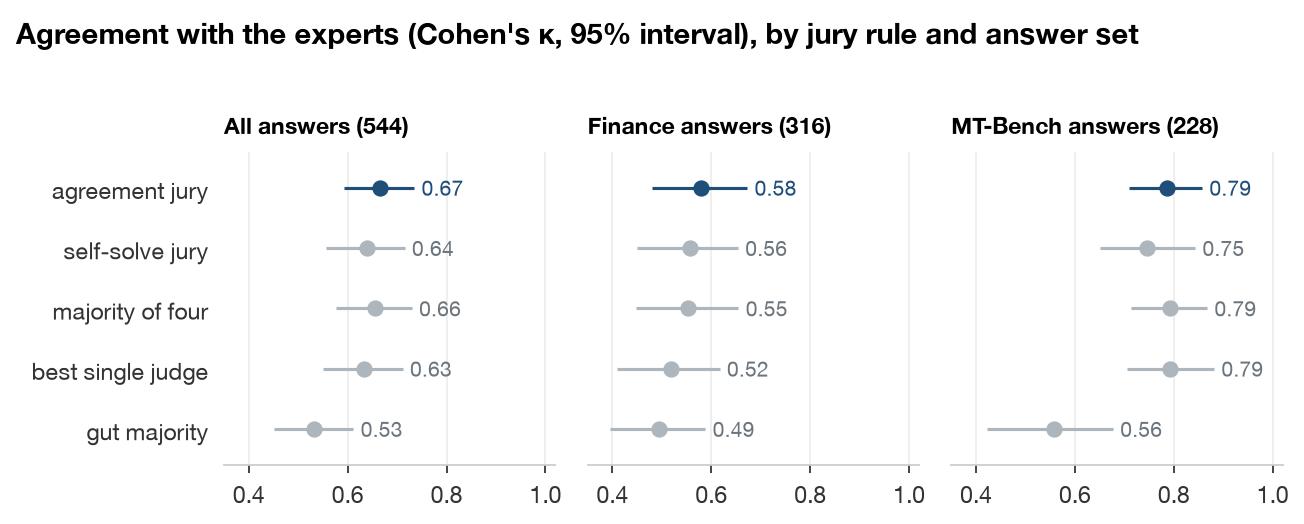

In [20]:
# Chart 1: agreement with the experts by jury rule, on all answers and on each answer set (results_by_rule.csv)
display(Image(filename=str(F.agreement_by_jury_rule(RES)), width=820, alt=F.ALT["agreement_by_jury_rule"]))

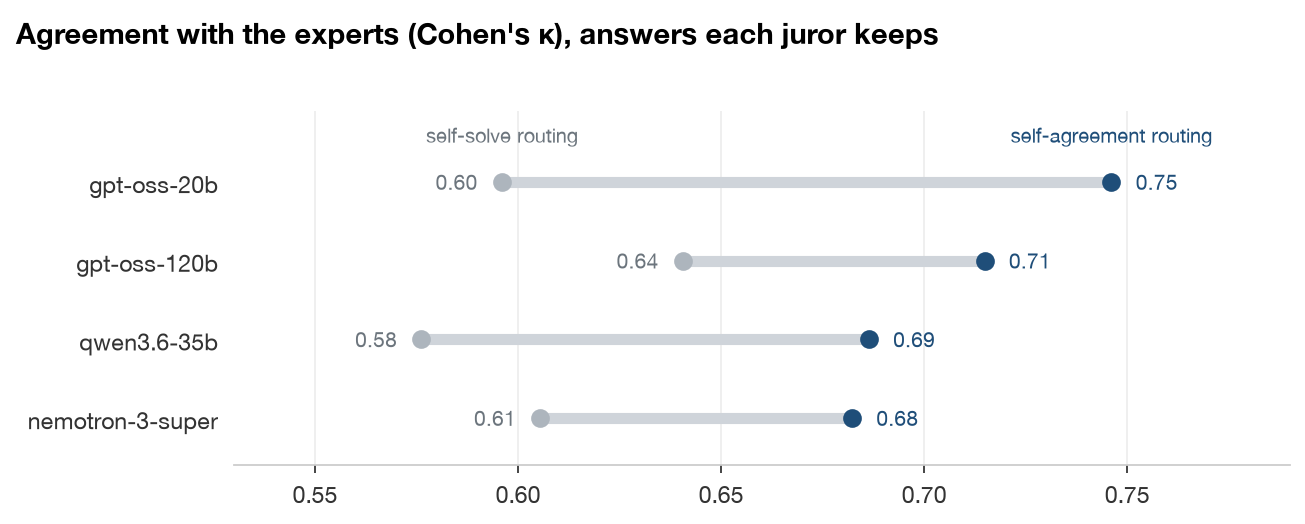

In [21]:
# Chart 2: each juror's κ on the answers it keeps, by routing rule, at matched coverage (matched_coverage.csv)
display(Image(filename=str(F.routing_at_matched_coverage(RES)), width=820, alt=F.ALT["routing_at_matched_coverage"]))

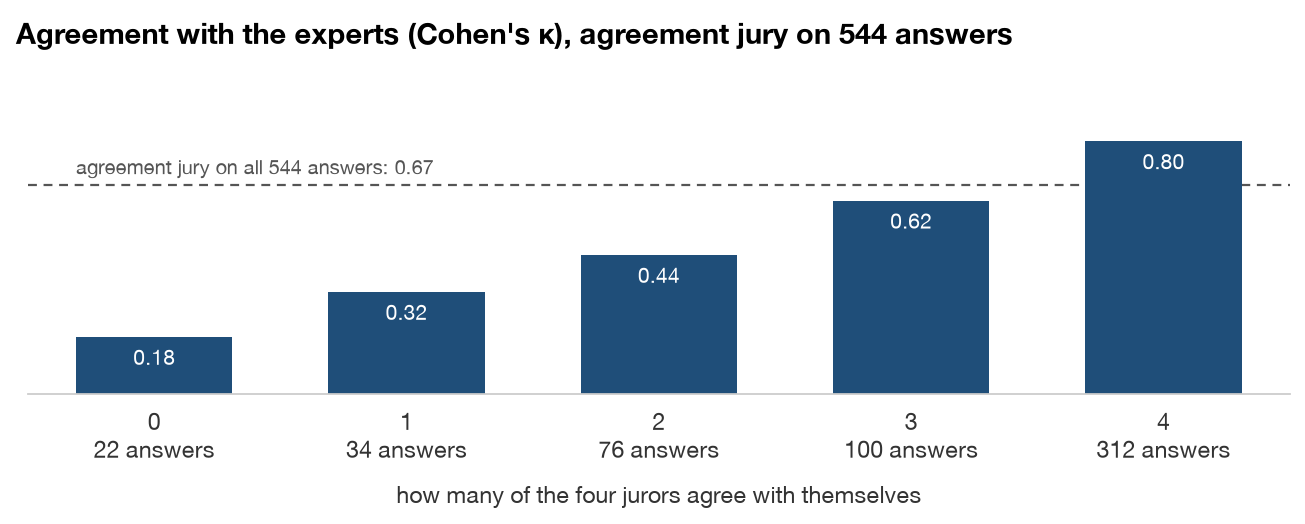

In [22]:
# Chart 3: the agreement jury's κ by how many jurors agree with themselves (kappa_by_juror_count.csv)
display(Image(filename=str(F.agreement_by_jurors_that_agree(RES)), width=820, alt=F.ALT["agreement_by_jurors_that_agree"]))

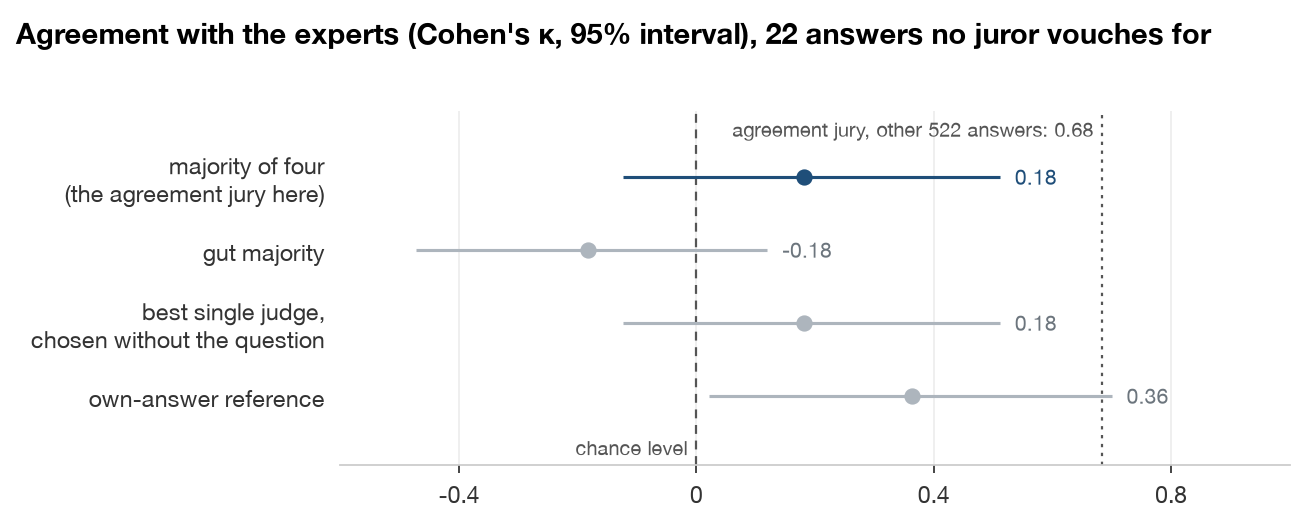

wrote results/figures/agreement_by_jurors_that_agree.png, results/figures/agreement_by_jury_rule.png, results/figures/routing_at_matched_coverage.png, results/figures/uncovered_answers_fallbacks.png


In [23]:
# Chart 4: each fallback's κ on the answers where no juror agrees with itself (uncovered_fallbacks.csv, coverage.csv)
display(Image(filename=str(F.uncovered_answers_fallbacks(RES)), width=820, alt=F.ALT["uncovered_answers_fallbacks"]))
print("wrote", ", ".join(sorted(str(p.relative_to(ROOT)) for p in (RES / "figures").glob("*.png"))))

## What the results say

- **Self-agreement routes better than self-solve.** At matched coverage it scores higher than self-solve routing for all four jurors, by +0.074 to +0.150 in κ, with the interval above 0 for three. Self-solve routing falls below the random 95th percentile for all four. No decision rule was set for this comparison.
- **Inside a jury the two signals tie.** The agreement jury reaches κ 0.666 on all 544 answers and the self-solve jury 0.640. The difference, +0.026 [-0.020, +0.072], is short of the +0.04 rule 1 needs.
- **No jury beats the best single judge.** Rule 2 is not met. The agreement jury is +0.033 [-0.011, +0.081] above gpt-oss-120b's reasoned read and +0.011 [-0.033, +0.052] above the majority of four. Three or five jurors give the same two outcomes.
- **Agreement with the experts rises with the number of jurors that agree.** The agreement jury's κ goes from 0.182 when no juror agrees with itself to 0.804 when all four do, on 312 answers. This grouping is descriptive and has no interval.
- **The answers no juror vouches for are where the jury is weakest.** On those 22 answers the majority of four reaches κ 0.182 [-0.123, 0.512]. The own-answer reference reaches 0.364 [0.021, 0.700], but on 22 answers the two intervals overlap widely. Sending the 22 to a person, untested here, keeps 96% of the answers automatic, at κ 0.684.
- **The self-solve gap test is in between.** On questions a juror could not solve, self-agreement still flags its errors with an AUROC of 0.640 [0.555, 0.721], against 0.730 where it solved them. That is below the 0.65 needed to hold and above the 0.60 needed to vanish, and the drop could be chance.
- **What limits the comparison.** Neither grader reached the 0.80 bar, so self-solve rests on qwen3.5-397b at κ 0.696. Two of six jurors were dropped at the screening. The best single judge was chosen with the expert labels. Routing is compared in κ, which depends on how many kept answers are labelled correct, and the plain-accuracy check in section 4 points the same way. Reading the first 40 answers again changed 0 to 3 reasoned verdicts per juror and 1 of the agreement jury.